# Stage 1 Data Analysis

### Imports

In [40]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mcap.reader import make_reader
from mcap_ros2.decoder import DecoderFactory

### Check on Topics

In [41]:
with open("data/stage-1-test-left-1/stage-1-test-left-1.mcap", "rb") as f:
    reader = make_reader(f)
    summary = reader.get_summary()
    for ch_id, ch in summary.channels.items():
        schema = summary.schemas[ch.schema_id]
        count = summary.statistics.channel_message_counts.get(ch_id, 0)
        print(f"{ch.topic:40s} {schema.name:40s} {count}")

/rosout                                  rcl_interfaces/msg/Log                   33
/events/write_split                      rosbag2_interfaces/msg/WriteSplitEvent   0
/parameter_events                        rcl_interfaces/msg/ParameterEvent        0
/tf                                      tf2_msgs/msg/TFMessage                   1179
/tf_static                               tf2_msgs/msg/TFMessage                   1
/vicon/athena/athena                     geometry_msgs/msg/PoseStamped            1177
/sensors/imu/raw                         sensor_msgs/msg/Imu                      353
/sensors/servo_position_command          std_msgs/msg/Float64                     48
/commands/motor/speed                    std_msgs/msg/Float64                     48
/commands/servo/position                 std_msgs/msg/Float64                     48
/ackermann_cmd                           ackermann_msgs/msg/AckermannDriveStamped 47


### Check on Vicon Datapoints

stage-1-test-left-1: 1177 Msg (0 deleted)
stage-1-test-left-2: 1414 Msg (0 deleted)
stage-1-test-left-3: 1384 Msg (0 deleted)
stage-1-test-right-1: 1425 Msg (0 deleted)
stage-1-test-right-2: 1453 Msg (1 deleted)
stage-1-test-right-3: 1546 Msg (0 deleted)
stage-1-test-straight-1: 1632 Msg (0 deleted)
stage-1-test-straight-2: 1521 Msg (215 deleted)
stage-1-test-straight-3: 1853 Msg (57 deleted)


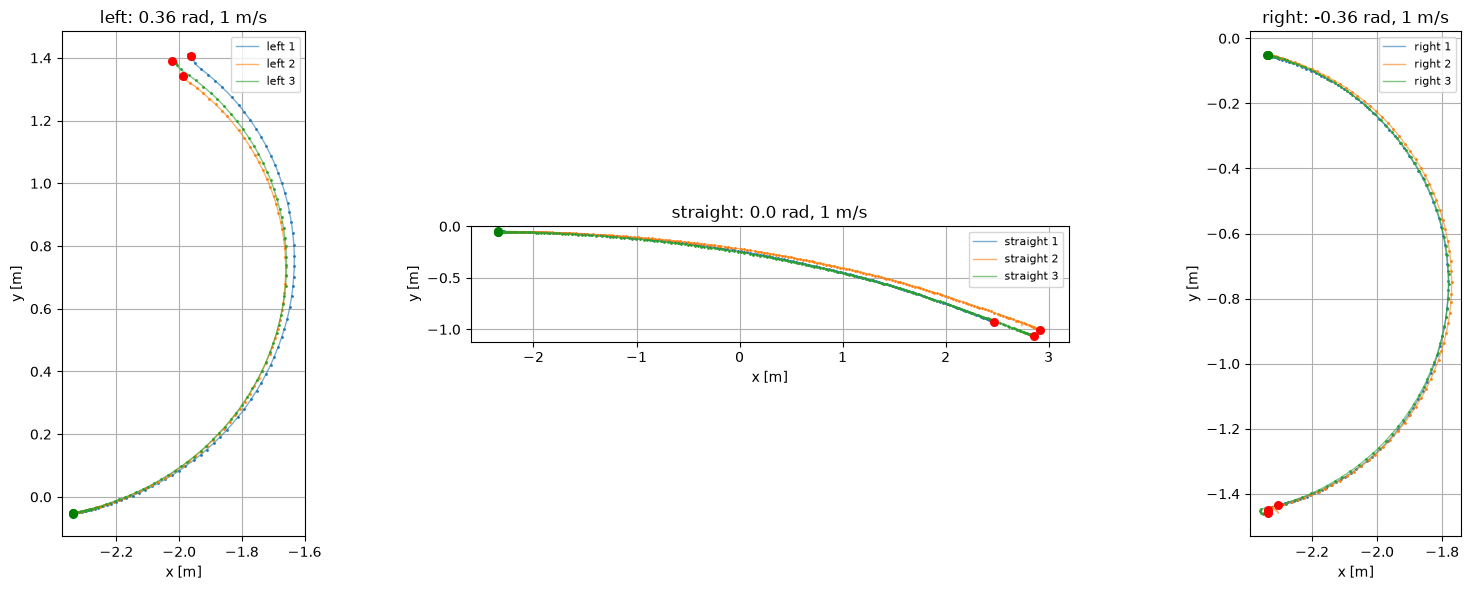

In [50]:
rootdir = "data-real/"
n = 5              
max_speed = 5.0    
groups = ["left", "straight", "right"]
titles = {
    "left":     "left: 0.36 rad, 1 m/s",
    "straight": "straight: 0.0 rad, 1 m/s",
    "right":    "right: -0.36 rad, 1 m/s",
}

def load_vicon(path, topic="/vicon/athena/athena"):
    rows = []
    with open(path, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])
        for schema, channel, message, msg in reader.iter_decoded_messages(topics=[topic]):
            p = msg.pose.position
            q = msg.pose.orientation
            rows.append({
                "t": message.log_time / 1e9,
                "px": p.x, "py": p.y, "pz": p.z,
                "qx": q.x, "qy": q.y, "qz": q.z, "qw": q.w,
            })
    return pd.DataFrame(rows)

def remove_jumps(df, max_speed=5.0, tol=0.01, origin_eps=1e-3):
    if df.empty:
        return df

    # 1) remove tracking errors by setting them to the origin
    at_origin = (df["px"].abs() < origin_eps) & (df["py"].abs() < origin_eps) & (df["pz"].abs() < origin_eps)
    df = df[~at_origin].reset_index(drop=True)
    if df.empty:
        return df

    # 2) remove outliers via speed
    t = df["t"].to_numpy()
    x = df["px"].to_numpy()
    y = df["py"].to_numpy()

    keep = np.zeros(len(df), dtype=bool)
    keep[0] = True
    last = 0
    for i in range(1, len(df)):
        dist = np.hypot(x[i] - x[last], y[i] - y[last])
        if dist <= max_speed * (t[i] - t[last]) + tol:
            keep[i] = True
            last = i
    return df[keep].reset_index(drop=True)

dfs = {g: {} for g in groups}
for subdir, dirs, files in os.walk(rootdir):
    for file in files:
        if not file.endswith(".mcap"):
            continue
        name = os.path.splitext(file)[0]
        
        m = re.search(r"(left|straight|right)-(\d+)", name)
        if not m:
            continue
        group, run = m.group(1), int(m.group(2))

        df = load_vicon(os.path.join(subdir, file))
        n_before = len(df)
        df = remove_jumps(df, max_speed=max_speed)
        print(f"{name}: {len(df)} Msg ({n_before - len(df)} deleted)")

        if not df.empty:
            dfs[group][run] = df

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors = plt.cm.tab10.colors

for ax, group in zip(axes, groups):
    for i, run in enumerate(sorted(dfs[group])):
        df = dfs[group][run]
        c = colors[i % len(colors)]
        ax.plot(df["px"], df["py"], "-", color=c, linewidth=1, alpha=0.6, label=f"{group} {run}")
        ax.plot(df["px"][::n], df["py"][::n], "o", color=c, markersize=1)
        ax.scatter(df["px"].iloc[0], df["py"].iloc[0], color="green", s=30, zorder=3)
        ax.scatter(df["px"].iloc[-1], df["py"].iloc[-1], color="red", s=30, zorder=3)

    ax.set_title(titles[group])
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_aspect("equal")
    ax.grid(True)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Error 